In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

BASE = '/content/drive/MyDrive/battery-cycling-quality-analytics'
DATA_PROCESSED = os.path.join(BASE, 'data', 'processed')
OUTPUTS = os.path.join(BASE, 'outputs', 'charts')
os.makedirs(OUTPUTS, exist_ok=True)

full = pd.read_parquet(os.path.join(DATA_PROCESSED, 'nasa_pcoe_long.parquet'))
print(f"Loaded {len(full):,} rows across {full['cell_id'].nunique()} cells")
print(f"Cells: {full['cell_id'].unique().tolist()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded 2,089,050 rows across 4 cells
Cells: ['B0005', 'B0006', 'B0007', 'B0018']


In [3]:
# Grab one row per (cell, cycle) for discharge cycles only
# capacity_Ah is the same value repeated across every sample row of a cycle,
# so .first() grabs the first occurrence per group
nasa_cap = (full[full['cycle_type'] == 'discharge']
            .groupby(['cell_id', 'cycle_number'])['capacity_Ah']
            .first()
            .reset_index()
            .rename(columns={'capacity_Ah': 'capacity_nasa_Ah'}))

print(f"NASA reported capacities: {len(nasa_cap):,} cycle-level rows")
print(nasa_cap.head())
print()
print(nasa_cap.groupby('cell_id').agg(
    n_cycles=('cycle_number', 'count'),
    cap_start=('capacity_nasa_Ah', 'max'),
    cap_end=('capacity_nasa_Ah', 'min'),
))

NASA reported capacities: 636 cycle-level rows
  cell_id  cycle_number  capacity_nasa_Ah
0   B0005             2          1.856487
1   B0005             4          1.846327
2   B0005             6          1.835349
3   B0005             8          1.835263
4   B0005            10          1.834646

         n_cycles  cap_start   cap_end
cell_id                               
B0005         168   1.856487  1.287453
B0006         168   2.035338  1.153818
B0007         168   1.891052  1.400455
B0018         132   1.855005  1.341051


In [7]:
# Discharge current is negative (current flowing OUT of the cell)
# Capacity (Ah) = integral of |I| dt / 3600  (seconds to hours)
# We use trapezoidal integration — the standard method

def compute_capacity(group):
    """
    For one discharge cycle (one (cell_id, cycle_number) group),
    integrate the magnitude of current over time to get capacity in Ah.
    """
    t = group['t_s'].values
    I = group['I'].values
    # trapezoidal integration of |I| over time, then convert seconds → hours
    charge_coulombs = np.trapz(np.abs(I), t)
    return charge_coulombs / 3600.0

ours = (full[full['cycle_type'] == 'discharge']
        .groupby(['cell_id', 'cycle_number'])
        .apply(compute_capacity, include_groups=False)
        .reset_index()
        .rename(columns={0: 'capacity_computed_Ah'}))

print(f"Our computed capacities: {len(ours):,} cycle-level rows")
print(ours.head())

Our computed capacities: 636 cycle-level rows
  cell_id  cycle_number  capacity_computed_Ah
0   B0005             2              1.862203
1   B0005             4              1.852078
2   B0005             6              1.841049
3   B0005             8              1.840912
4   B0005            10              1.840360


/tmp/ipykernel_3776/848273404.py:13: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  charge_coulombs = np.trapz(np.abs(I), t)


In [8]:
# Merge NASA's number with our computed number
cap = nasa_cap.merge(ours, on=['cell_id', 'cycle_number'])

# How well do they agree?
cap['abs_error_Ah'] = (cap['capacity_nasa_Ah'] - cap['capacity_computed_Ah']).abs()
cap['pct_error'] = 100 * cap['abs_error_Ah'] / cap['capacity_nasa_Ah']

print("Agreement between NASA-reported and our computed capacity:")
print(cap[['abs_error_Ah', 'pct_error']].describe())
print()
print("Worst 5 cycles (biggest disagreement):")
print(cap.nlargest(5, 'pct_error')[['cell_id', 'cycle_number', 'capacity_nasa_Ah', 'capacity_computed_Ah', 'pct_error']])

Agreement between NASA-reported and our computed capacity:
       abs_error_Ah   pct_error
count    636.000000  636.000000
mean       0.013055    0.841618
std        0.007435    0.495490
min        0.000000    0.000000
25%        0.005626    0.309459
50%        0.013418    0.877819
75%        0.018711    1.245351
max        0.028022    1.722345

Worst 5 cycles (biggest disagreement):
    cell_id  cycle_number  capacity_nasa_Ah  capacity_computed_Ah  pct_error
501   B0007           608          1.400455              1.424576   1.722345
499   B0007           600          1.406171              1.430325   1.717713
500   B0007           604          1.406336              1.430418   1.712388
497   B0007           592          1.410840              1.434976   1.710772
498   B0007           596          1.410995              1.435130   1.710526


Saved → /content/drive/MyDrive/battery-cycling-quality-analytics/outputs/charts/04_capacity_fade_all_cells.png


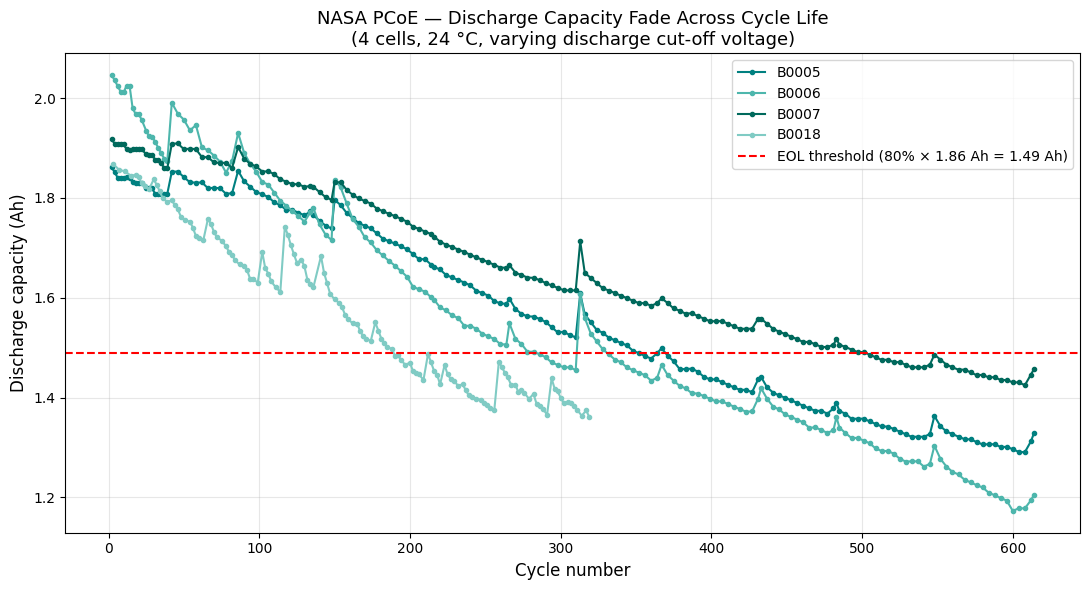

In [9]:
# Use our computed capacity for the main plot (it's the one we trust)
fig, ax = plt.subplots(figsize=(11, 6))

# Teal palette — 4 distinct shades for 4 cells
palette = {
    'B0005': '#008080',  # core teal
    'B0006': '#4db6ac',  # lighter teal
    'B0007': '#00695c',  # deeper teal
    'B0018': '#80cbc4',  # pale teal
}

for cell_id, color in palette.items():
    d = cap[cap['cell_id'] == cell_id].sort_values('cycle_number')
    if len(d) == 0:
        continue
    ax.plot(d['cycle_number'], d['capacity_computed_Ah'],
            marker='o', markersize=3, linewidth=1.5,
            color=color, label=cell_id)

# Industry convention: 80% of initial capacity = end-of-life (EOL)
# Use B0005's starting capacity as the reference
cap_start = cap[cap['cell_id'] == 'B0005']['capacity_computed_Ah'].max()
eol_threshold = 0.80 * cap_start
ax.axhline(eol_threshold, color='red', linestyle='--', linewidth=1.5,
           label=f'EOL threshold (80% × {cap_start:.2f} Ah = {eol_threshold:.2f} Ah)')

ax.set_xlabel('Cycle number', fontsize=12)
ax.set_ylabel('Discharge capacity (Ah)', fontsize=12)
ax.set_title('NASA PCoE — Discharge Capacity Fade Across Cycle Life\n(4 cells, 24 °C, varying discharge cut-off voltage)',
             fontsize=13)
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()

out_path = os.path.join(OUTPUTS, '04_capacity_fade_all_cells.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f"Saved → {out_path}")

plt.show()

In [10]:
cap_out = os.path.join(DATA_PROCESSED, 'nasa_pcoe_cycle_level.parquet')
cap.to_parquet(cap_out, compression='snappy')
print(f"Saved cycle-level DataFrame → {cap_out}")

Saved cycle-level DataFrame → /content/drive/MyDrive/battery-cycling-quality-analytics/data/processed/nasa_pcoe_cycle_level.parquet
